# Funnel Analysis: From Visits to Purchases
Business question: at which stage do visitors drop off the most,
and do any segments behave differently?
Data: Synthetic Web Analytics Funnel Events (GenerateRealData, CC BY 4.0).

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

con = sqlite3.connect("../data/web_funnel_events.sqlite")
for t in ["users", "sessions", "events", "conversions"]:
    n = pd.read_sql(f"SELECT COUNT(*) AS n FROM {t}", con) ["n"][0]
    print(t,n)

users 30000
sessions 84000
events 304309
conversions 7609


In [2]:
#MUAT SEMUA TABEL
users = pd.read_sql("SELECT * FROM users", con)
sessions = pd.read_sql("SELECT * FROM sessions", con)
events = pd.read_sql("SELECT * FROM events", con)
conversions = pd.read_sql("SELECT * FROM conversions", con)

sessions.head()

,session_id,user_id,started_at,device,browser,referrer,landing_page,duration_s
0,1,17523,2026-09-02 03:59:22,mobile,Edge,direct,/,136
1,2,11552,2026-09-04 03:40:17,mobile,Chrome,direct,/,183
2,3,5703,2026-08-22 16:17:22,mobile,Safari,direct,/p/trail-runner-x,171
3,4,19059,2026-09-09 17:37:42,desktop,Edge,bing,/category/tents,116
4,5,17737,2026-09-19 19:15:57,mobile,Safari,direct,/,170


In [3]:
#CEK KUALITAS DATA
for name, df in {"users": users, "sessions": sessions, "events": events, "conversions": conversions}.items():
    print(name, df.shape, "| kosong:", int(df.isna().sum().sum()),
    "| duplikat:", int(df.duplicated().sum()))

users (30000, 6) | kosong: 0 | duplikat: 0
sessions (84000, 8) | kosong: 0 | duplikat: 0
events (304309, 8) | kosong: 0 | duplikat: 0
conversions (7609, 6) | kosong: 6098 | duplikat: 0


In [4]:
#UBAH KOLOM TANGGAL
users["signup_date"] = pd.to_datetime(users["signup_date"])
sessions["started_at"] = pd.to_datetime(sessions["started_at"])
events["occurred_at"] = pd.to_datetime(events["occurred_at"])
conversions["converted_at"] = pd.to_datetime(conversions["converted_at"])

In [5]:
#QUERY FUNNEL
funnel = pd.read_sql("""
SELECT
    COUNT(DISTINCT session_id) AS sessions,
    COUNT(DISTINCT CASE WHEN event_name='view_product'  THEN session_id END) AS viewed,
    COUNT(DISTINCT CASE WHEN event_name='add_to_cart'   THEN session_id END) AS carted,
    COUNT(DISTINCT CASE WHEN event_name='begin_checkout'THEN session_id END) AS checkout,
    COUNT(DISTINCT CASE WHEN event_name='purchase'      THEN session_id END) AS purchased
FROM events
""", con)
funnel

,sessions,viewed,carted,checkout,purchased
0,84000,56579,22665,12844,7609


In [9]:
#TABEL FUNNEL
stages = ["Sessions Started", "Viewed Product", "Added to Cart", "Began Checkout", "Purchased"]
tbl = pd.DataFrame({"stage": stages, "sessions": funnel.iloc[0].values})
tbl["step_conversion_%"] = (tbl["sessions"] / tbl["sessions"].shift(1) * 100).round(1)
tbl["drop_off_%"] = (100 - tbl["step_conversion_%"]).round(1)
tbl["overall_conversion_%"] = (tbl["sessions"] / tbl["sessions"].iloc[0] * 100).round(2)
tbl

,stage,sessions,step_conversion_%,drop_off_%,overall_conversion_%
0,Sessions Started,84000,NaN,NaN,100.00
1,Viewed Product,56579,67.4,32.6,67.36
2,Added to Cart,22665,40.1,59.9,26.98
3,Began Checkout,12844,56.7,43.3,15.29
4,Purchased,7609,59.2,40.8,9.06


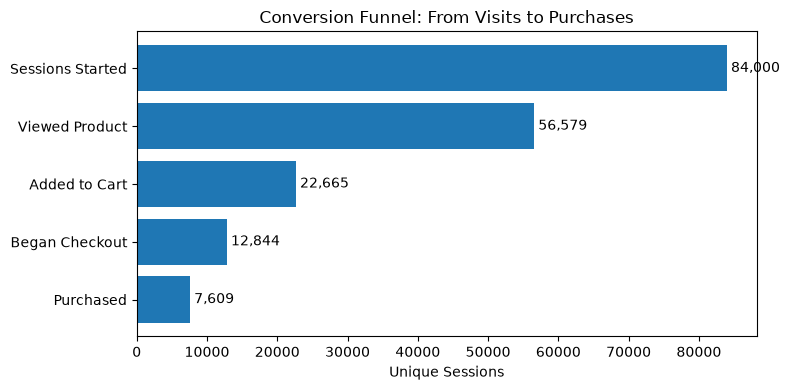

In [10]:
#Grafik Funnel
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(tbl["stage"][::-1], tbl["sessions"][::-1])
ax.set_xlabel("Unique Sessions")
ax.set_title("Conversion Funnel: From Visits to Purchases")
for i, v in enumerate(tbl["sessions"][::-1]):
    ax.text(v, i, f" {v:,}", va="center")
plt.tight_layout()
plt.show()

## Key Finding
The biggest drop-off occurs between *Viewed Product* and *Added to Cart*, where 59.9% of sessions leave. Overall conversion is 9.06%.